1) Defining constants

In [3]:
using LinearAlgebra
using Plots
using Trapz  
using Statistics

# Constants for Re=2500 in the ONERA tunnel (H. Kahalerras, Y. Malécot, Y. Gagne, B. Castaing, Intermittency and Reynolds number, Phys. Fluids 10 (1998))
#c1 = 0.37

c2 = 0.025
c1 = 1/3 + 3/2 * c2
L = 0.0302    #(in m)
σ = 1.0      #(in m^2/s^2)

#l = 0.0100    # Arbitrary choice. (in m, knowing that η=0.000307 m, l must be << L)

1.0

2. Defining functions

In [4]:
# Function
f(h, l, v) = log(l/L) * ((h - c1)^2 / (2c2) - h) - 0.5 * (v/σ)^2 * (l/L)^(-2h)

# First derivative f'(h, l, v) selon h
fprime(h, l, v) = log(l/L) * ((h - c1)/c2 - 1 + (v/σ)^2 * (l/L)^(-2h))

# Second derivative f''(h, l, v) selon h
fsecond(h, l, v) = log(l/L) * (1/c2 - 2 * (v/σ)^2 * log(l/L) * (l/L)^(-2h))

# Value of h_star
using LambertW
h_star(l, v) = (c1 + c2) - lambertw(2 * c2 * abs(log(l / L)) * ((l * v / σ)^2) * exp(2 * (c1 + c2) * abs(log(l / L)))) / (2 * abs(log(l / L)))
#h_star(l, v) = c1


h_star (generic function with 1 method)

3. Computation and plot (Laplace approximation)

3.1. Display h* values

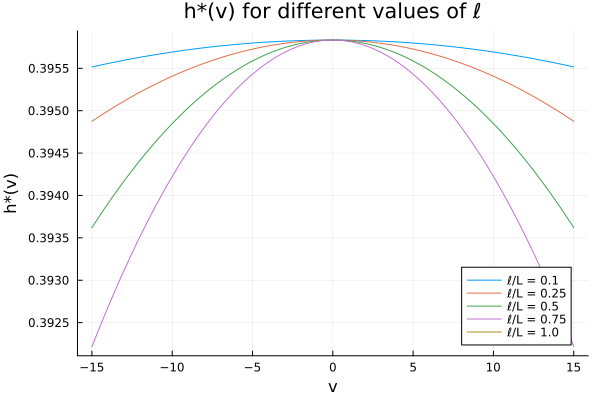

In [5]:
using Plots

# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define v values
v_values = -15:0.01:15

# Create the plot for h*(v)
p = plot(title = "h*(v) for different values of ℓ",
         xlabel = "v",
         ylabel = "h*(v)",
         lw = 2)

# Loop over each l and plot the corresponding h*(v)
for l in l_values
    h_values = [h_star(l, v) for v in v_values]
    plot!(p, v_values, h_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Display the final plot
display(p)

3.2. Compute the pdf for one value (Laplace approximation)

In [20]:
function compute_P_δlu_of_v(l, v; tol=1e-10, maxiter=100)
    # Asserts the validity of the Laplace point (f'' must be < 0)
    if fsecond(h_star(l, v), l, v) >= 0 || isnan(fsecond(h_star(l, v), l, v))
        return 0.0
    end

    prefactor = (1 / σ) * sqrt((-log(l/L)) / ((2π)^2 * c2)) * sqrt(2π / (-fsecond(h_star(l, v), l, v)))
    exponent = f(h_star(l, v), l, v)

    exponent = clamp(exponent, -700, 700)
    return prefactor * exp(exponent)
end


compute_P_δlu_of_v (generic function with 1 method)

3.3. Plot the pdf and its log  (Laplace approximation)

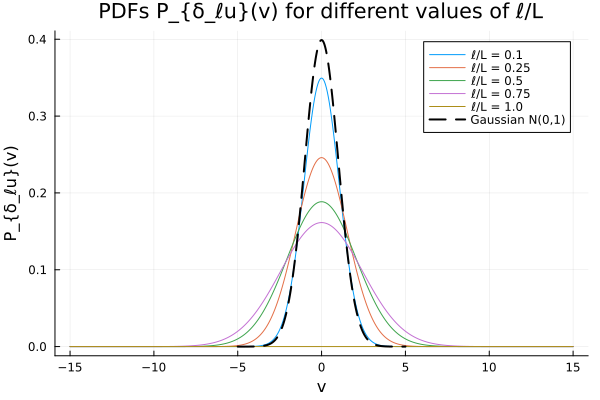

In [5]:
using Distributions, Plots

# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define v values
v_values = -15:0.01:15

# Create the plot for P_{δlu}(v)
p1 = plot(title = "PDFs P_{δ_ℓu}(v) for different values of ℓ/L",
          xlabel = "v",
          ylabel = "P_{δ_ℓu}(v)",
          lw = 2)

# Loop over each l and plot the corresponding density
for l in l_values
    P_values = [compute_P_δlu_of_v(l, v) for v in v_values]
    plot!(p1, v_values, P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
v_gauss = -5:0.01:5
P_gauss = pdf.(gauss, v_gauss)
plot!(p1, v_gauss, P_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


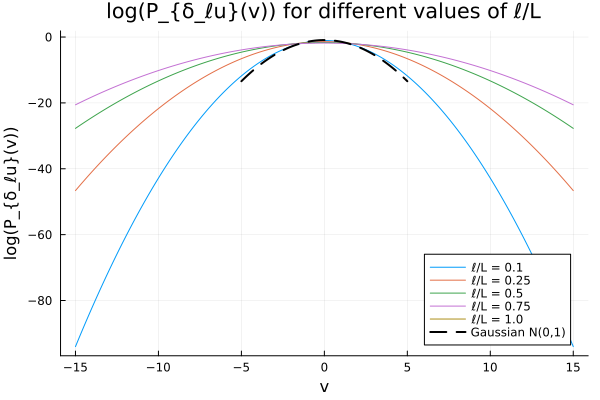

In [6]:
using Distributions, Plots

# Define l values
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Define v values
v_values = -15:0.01:15

# Create the plot for log(P_{δlu}(v))
p1 = plot(title = "log(P_{δ_ℓu}(v)) for different values of ℓ/L",
          xlabel = "v",
          ylabel = "log(P_{δ_ℓu}(v))",
          lw = 2)

# Loop over each l and plot log(P_{δlu}(v))
for l in l_values
    P_values = [compute_P_δlu_of_v(l, v) for v in v_values]
    log_P_values = [log(P) for P in P_values if P > 0]  # avoid log(0)
    valid_v = [v for (v, P) in zip(v_values, P_values) if P > 0]
    plot!(p1, valid_v, log_P_values, label = "ℓ/L = $(round(l/L, digits=2))")
end

# Add standard Gaussian for reference
gauss = Normal(0, 1)
v_gauss = -5:0.01:5
P_gauss = pdf.(gauss, v_gauss)
logP_gauss = log.(P_gauss)
plot!(p1, v_gauss, logP_gauss, label = "Gaussian N(0,1)", lw = 2, ls = :dash, color = :black)

# Display the final plot
display(p1)


3.4. Plotting the normalized PDF and its log  (Laplace approximation)

In [ ]:
# Fonction pour calculer la PDF normalisée
function computeNormalizedPdf(l, nu; tol=1e-10, maxiter=100)
    # Calculer le facteur de normalisation
    normFactor = (L/l)^(c1 + 2*c2)
    
    # Convertir de nu à u
    u = nu / normFactor
    
    # Utiliser la fonction existante avec u
    return compute_P_δlu_of_v(l, u, tol=tol, maxiter=maxiter) 
end


computeNormalizedPdf (generic function with 1 method)

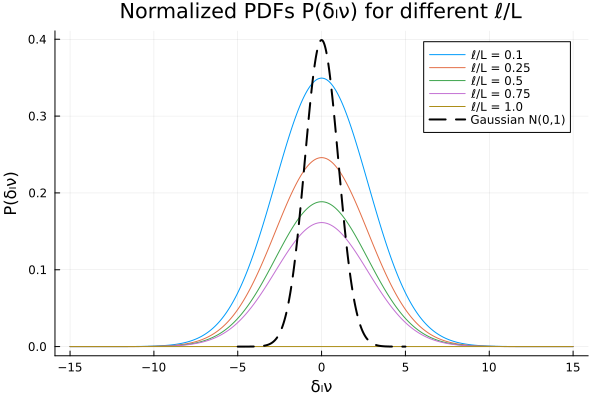

In [8]:

# Plot de la PDF normalisée
using Plots

# Définir les valeurs de l
l_values = [0.10 * L, 0.25 * L, 0.5 * L, 0.75 * L, L]

# Définir les valeurs de nu (incrément normalisé)
nu_values = -15.0:0.01:15

# Créer le plot pour la PDF normalisée
p_norm = plot(title="Normalized PDFs P(δₗν) for different ℓ/L",
              xlabel="δₗν",
              ylabel="P(δₗν)",
              lw=2)

# Boucle sur chaque l et plot de la PDF normalisée correspondante
for l in l_values
    P_values = [computeNormalizedPdf(l, nu) for nu in nu_values]
    plot!(p_norm, nu_values, P_values, label="ℓ/L = $(round(l/L, digits=2))")
end

# Ajouter une Gaussienne standard pour référence
using Distributions
gauss = Normal(0, 1)
nu_gauss = -5.0:0.01:5
P_gauss = pdf.(gauss, nu_gauss)
plot!(p_norm, nu_gauss, P_gauss, label="Gaussian N(0,1)", lw=2, ls=:dash, color=:black)

display(p_norm)


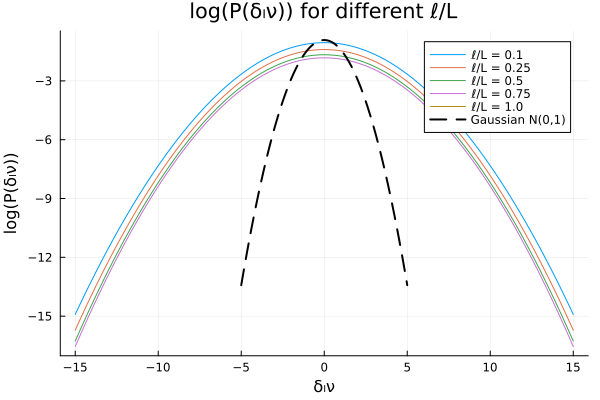

In [9]:
# Plot de log(P) pour la PDF normalisée
p_log_norm = plot(title="log(P(δₗν)) for different ℓ/L",
                  xlabel="δₗν",
                  ylabel="log(P(δₗν))",
                  lw=2)

# Boucle sur chaque l
for l in l_values
    P_values = [computeNormalizedPdf(l, nu) for nu in nu_values]
    log_P_values = [log(P) for P in P_values if P > 0]
    valid_nu = [nu for (nu, P) in zip(nu_values, P_values) if P > 0]
    plot!(p_log_norm, valid_nu, log_P_values, label="ℓ/L = $(round(l/L, digits=2))")
end

# Ajouter la Gaussienne pour référence
log_P_gauss = log.(P_gauss)
plot!(p_log_norm, nu_gauss, log_P_gauss, label="Gaussian N(0,1)", lw=2, ls=:dash, color=:black)

display(p_log_norm)


4. Full PDF Computation

In [33]:
#grid definition:

# h-grid (singularity exponent)
dh = 1/1000
hmin = 0.0
hmax = 1.0
h = hmin:dh:(hmax-dh)
h = collect(h)  

# D(h) function
D = @. 1 - ((h - c1)^2) / (2 * c2)

# Velocity increment grid
umin = -20.0
umax = 20.0
ustep = 0.01
delta_l_u = umin:ustep:(umax-ustep)
delta_l_u = collect(delta_l_u)

# Scale grid
ls = collect((0.1:0.1:0.9) .* L)

9-element Vector{Float64}:
 0.00302
 0.00604
 0.00906
 0.01208
 0.0151
 0.01812
 0.02114
 0.02416
 0.027180000000000003

In [34]:
# Initialize arrays
P_delta = zeros(length(delta_l_u), length(h))
P_delta_l_u = zeros(length(delta_l_u), length(ls))

# Compute full PDFs via numerical integration
for il in 1:length(ls)
    l = ls[il]
    
    # Compute P_h (h-distribution at scale l)
    integrand_h = (l/L) .^ D
    norm_factor = trapz(h, integrand_h)
    P_h = integrand_h / norm_factor
    
    # Compute P_delta for each velocity increment
    for iu in 1:length(delta_l_u)
        beta_l = (l/L) .^ (-h)
        P_delta[iu, :] = (1/σ) .* beta_l .* 
                         exp.(-0.5 .* (delta_l_u[iu] ./ (σ .* beta_l)).^2) ./ 
                         sqrt(2 * π)
    end
    
    # Integrate over h to get full PDF
    for iu in 1:length(delta_l_u)
        P_delta_l_u[iu, il] = trapz(h, P_delta[iu, :] .* P_h)
    end
end

# Ensure full PDF columns are normalized and avoid zeros for log-scale plotting
for il in 1:length(ls)
    norm_full = trapz(delta_l_u, P_delta_l_u[:, il])
    if norm_full > 0
        P_delta_l_u[:, il] .= P_delta_l_u[:, il] ./ norm_full
    end
    # floor to tiny positive to avoid log(0) issues
    P_delta_l_u[:, il] .= max.(P_delta_l_u[:, il], 1e-300)
end

5.  h* = c1 approximation

In [36]:
# Compute PDFs using h* = c1 (saddle point approximation)
P_delta_l_u_hstar = zeros(length(delta_l_u), length(ls))

for il in 1:length(ls)
    l = ls[il]
    hstar = c1
    
    beta_l_star = (l/L)^(-hstar)
    P_delta_l_u_hstar[:, il] = (1/σ) .* beta_l_star .* 
                                exp.(-0.5 .* (delta_l_u ./ (σ * beta_l_star)).^2) ./ 
                                sqrt(2 * π)
    
    # Normalize
    norm = trapz(delta_l_u, P_delta_l_u_hstar[:, il])
    P_delta_l_u_hstar[:, il] = P_delta_l_u_hstar[:, il] ./ norm
end


6. Comparing all PDFs

In [37]:
# Preallocate array for Laplace approximation
P_delta_l_u_laplace = zeros(length(delta_l_u), length(ls))

for il in 1:length(ls)
    l = ls[il]
    # evaluate Laplace approx at each u = delta_l_u
    Pvec = [compute_P_δlu_of_v(l, u) for u in delta_l_u]
    # guard against NaNs / negatives (correct syntax)
    Pvec = [ (isfinite(x) && x >= 0.0) ? x : 0.0 for x in Pvec ]
    # normalize on the u-grid
    norm = trapz(delta_l_u, Pvec)
    if norm > 0
        Pvec .= Pvec ./ norm
    end
    P_delta_l_u_laplace[:, il] = Pvec
end

P_delta_l_u_laplace .= max.(P_delta_l_u_laplace, 1e-300)
P_delta_l_u_hstar .= max.(P_delta_l_u_hstar, 1e-300)

4000×9 Matrix{Float64}:
 3.05419e-17  1.03298e-27  6.96383e-37  …  9.00613e-75  1.7947e-81
 3.16692e-17  1.09752e-27  7.55794e-37     1.06692e-74  2.15924e-81
 3.28376e-17  1.16606e-27  8.2024e-37      1.26382e-74  2.59759e-81
 3.40484e-17  1.23884e-27  8.90144e-37     1.49694e-74  3.12464e-81
 3.53032e-17  1.31612e-27  9.65967e-37     1.77291e-74  3.75828e-81
 3.66036e-17  1.39819e-27  1.04821e-36  …  2.09957e-74  4.52e-81
 3.79512e-17  1.48532e-27  1.1374e-36      2.48621e-74  5.4356e-81
 3.93477e-17  1.57784e-27  1.23413e-36     2.94381e-74  6.53607e-81
 4.07949e-17  1.67607e-27  1.33904e-36     3.48533e-74  7.8586e-81
 4.22945e-17  1.78036e-27  1.4528e-36      4.12612e-74  9.44786e-81
 ⋮                                      ⋱               
 4.22945e-17  1.78036e-27  1.4528e-36      4.12612e-74  9.44786e-81
 4.07949e-17  1.67607e-27  1.33904e-36     3.48533e-74  7.8586e-81
 3.93477e-17  1.57784e-27  1.23413e-36     2.94381e-74  6.53607e-81
 3.79512e-17  1.48532e-27  1.1374e-36     

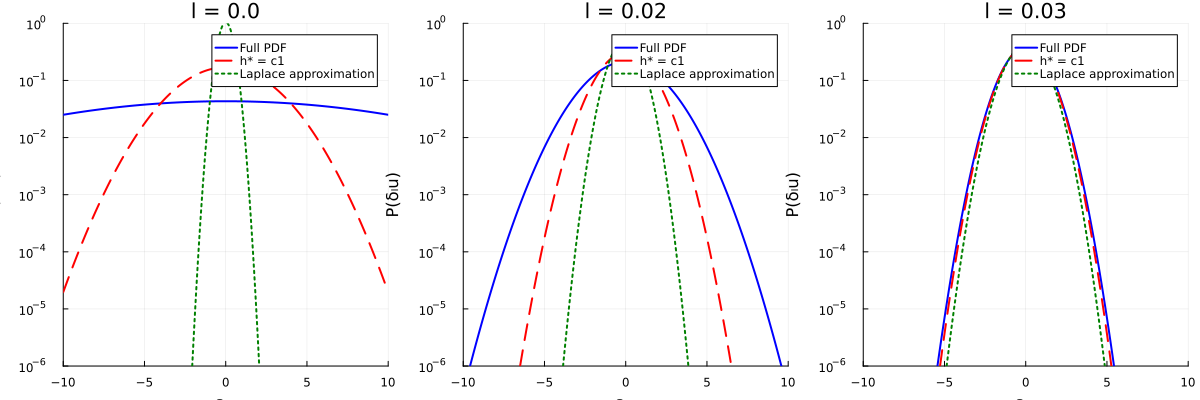

In [38]:
# Plot comparison for selected scales
p1 = plot(layout=(1,3), size=(1200, 400))

scale_indices = [1, 5, 9]  # l=0.1, 0.5, 0.9

for (i, il) in enumerate(scale_indices)
    # Full PDF
    plot!(p1[i], delta_l_u, P_delta_l_u[:, il], 
          yscale=:log10, label="Full PDF", 
          linewidth=2, color=:blue)
    
    # h* = c1
    plot!(p1[i], delta_l_u, P_delta_l_u_hstar[:, il], 
          yscale=:log10, label="h* = c1", 
          linewidth=2, linestyle=:dash, color=:red)
    
    # Laplace approximation 
    plot!(p1[i], delta_l_u, P_delta_l_u_laplace[:, il], 
           yscale=:log10, label="Laplace approximation", 
           linewidth=2, linestyle=:dot, color=:green)
    
    xlabel!(p1[i], "δₗu")
    ylabel!(p1[i], "P(δₗu)")
    title!(p1[i], "l = $(round(ls[il], digits=2))")
    xlims!(p1[i], (-10, 10))
    ylims!(p1[i], (1e-6, 1))
end

plot!(p1, legend=:topright)
display(p1)
